In [23]:
# STEP 1: tools and files
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, roc_auc_score, confusion_matrix
from google.colab import files

warnings.filterwarnings("ignore")
uploaded = files.upload()      # pick all 4 files together

Saving dataset.csv to dataset (2).csv
Saving symptom_Description.csv to symptom_Description (2).csv
Saving symptom_precaution.csv to symptom_precaution (2).csv
Saving healthcare-dataset-stroke-data.csv to healthcare-dataset-stroke-data (2).csv


In [24]:
# STEP 2: read the files
symptoms = pd.read_csv("dataset.csv")
desc = pd.read_csv("symptom_Description.csv")
prec = pd.read_csv("symptom_precaution.csv")
stroke = pd.read_csv("healthcare-dataset-stroke-data.csv")
print("Symptom data:", symptoms.shape)
print("Stroke data:", stroke.shape)
print(symptoms.head(3))
print(stroke.head(3))

Symptom data: (4920, 18)
Stroke data: (5110, 12)
            Disease   Symptom_1              Symptom_2              Symptom_3  \
0  Fungal infection     itching              skin_rash   nodal_skin_eruptions   
1  Fungal infection   skin_rash   nodal_skin_eruptions    dischromic _patches   
2  Fungal infection     itching   nodal_skin_eruptions    dischromic _patches   

              Symptom_4 Symptom_5 Symptom_6 Symptom_7 Symptom_8 Symptom_9  \
0   dischromic _patches       NaN       NaN       NaN       NaN       NaN   
1                   NaN       NaN       NaN       NaN       NaN       NaN   
2                   NaN       NaN       NaN       NaN       NaN       NaN   

  Symptom_10 Symptom_11 Symptom_12 Symptom_13 Symptom_14 Symptom_15  \
0        NaN        NaN        NaN        NaN        NaN        NaN   
1        NaN        NaN        NaN        NaN        NaN        NaN   
2        NaN        NaN        NaN        NaN        NaN        NaN   

  Symptom_16 Symptom_17  
0     

In [25]:
# STEP 3: clean the symptom data
# each row lists the symptoms of one patient, so we turn it into yes/no (1/0) columns
symptom_cols = []
for c in symptoms.columns:
    if c.startswith("Symptom"):
        symptom_cols.append(c)

for c in symptom_cols:
    symptoms[c] = symptoms[c].fillna("").astype(str).str.strip()
symptoms["Disease"] = symptoms["Disease"].astype(str).str.strip()

all_symptoms = set()
for c in symptom_cols:
    all_symptoms.update(symptoms[c].unique())
all_symptoms.discard("")
all_symptoms.discard("nan")
all_symptoms = sorted(all_symptoms)

X_sym = pd.DataFrame()
for s in all_symptoms:
    X_sym[s] = (symptoms[symptom_cols] == s).any(axis=1).astype(int)
y_sym = symptoms["Disease"]
print("Symptom columns:", X_sym.shape[1], " Diseases:", y_sym.nunique())

Symptom columns: 131  Diseases: 41


In [26]:
# STEP 4: clean the stroke data
# bmi has some blanks, fill them with the middle value (median)
stroke["bmi"] = stroke["bmi"].fillna(stroke["bmi"].median())
# smoking: 0 = never / unknown, 1 = used to smoke, 2 = smokes now
stroke["smoking"] = stroke["smoking_status"].map({"never smoked": 0, "Unknown": 0, "formerly smoked": 1, "smokes": 2})
stroke_features = ["age", "hypertension", "heart_disease", "avg_glucose_level", "bmi", "smoking"]
X_str = stroke[stroke_features]
y_str = stroke["stroke"]
print("Stroke cases:", y_str.sum(), "out of", len(y_str))

Stroke cases: 249 out of 5110


Disease
Fungal infection       120
Allergy                120
GERD                   120
Chronic cholestasis    120
Drug Reaction          120
Peptic ulcer diseae    120
AIDS                   120
Diabetes               120
Gastroenteritis        120
Bronchial Asthma       120
Name: count, dtype: int64


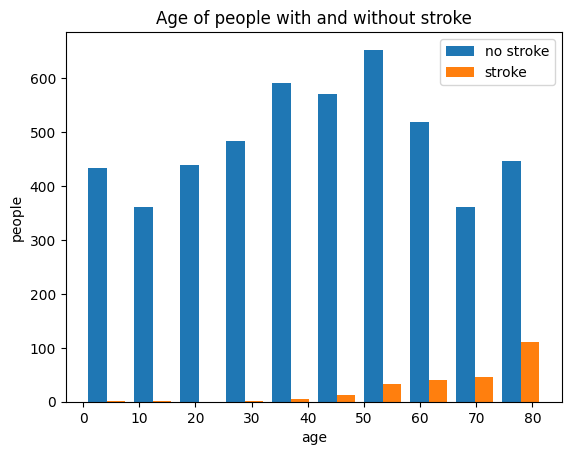

age                  0.25
hypertension         0.13
heart_disease        0.13
avg_glucose_level    0.13
bmi                  0.04
smoking              0.04
stroke               1.00
Name: stroke, dtype: float64


In [27]:
# STEP 5: look at the data
print(y_sym.value_counts().head(10))
plt.hist([stroke[y_str == 0]["age"], stroke[y_str == 1]["age"]], bins=10, label=["no stroke", "stroke"])
plt.xlabel("age")
plt.ylabel("people")
plt.legend()
plt.title("Age of people with and without stroke")
plt.show()
print(stroke[stroke_features + ["stroke"]].corr()["stroke"].round(2))

In [28]:
# STEP 6: hypothesis test
# question: is the average age of stroke patients different from the others?
age_stroke = stroke[y_str == 1]["age"]
age_other = stroke[y_str == 0]["age"]
t, p = stats.ttest_ind(age_stroke, age_other)
print("average age with stroke:", round(age_stroke.mean(), 1), " without:", round(age_other.mean(), 1))
print("p-value:", p)
if p < 0.05:
    print("The difference is real, age matters.")
else:
    print("No clear difference.")

average age with stroke: 67.7  without: 42.0
p-value: 7.0307775129939774e-71
The difference is real, age matters.


In [29]:
# STEP 7: split into practice rows and exam rows
Xs_train, Xs_test, ys_train, ys_test = train_test_split(X_sym, y_sym, test_size=0.2, random_state=42)
Xt_train, Xt_test, yt_train, yt_test = train_test_split(X_str, y_str, test_size=0.2, random_state=42, stratify=y_str)

scaler = StandardScaler()
Xt_train_s = scaler.fit_transform(Xt_train)
Xt_test_s = scaler.transform(Xt_test)

In [30]:
# STEP 8: symptom checker, try three algorithms
sym_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(max_depth=20, random_state=42),
}
sym_scores = {}
for name in sym_models:
    score = cross_val_score(sym_models[name], Xs_train, ys_train, cv=5, scoring="accuracy").mean()
    sym_scores[name] = score
    print(name, "practice score:", round(score, 3))

Logistic Regression practice score: 1.0
KNN practice score: 1.0
Decision Tree practice score: 0.544


In [31]:
# STEP 9: stroke risk, try three algorithms
# only a few people have a stroke, so class_weight="balanced" gives them more importance
str_models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42),
}
str_auc = {}
str_recall = {}
for name in str_models:
    str_auc[name] = cross_val_score(str_models[name], Xt_train_s, yt_train, cv=5, scoring="roc_auc").mean()
    str_recall[name] = cross_val_score(str_models[name], Xt_train_s, yt_train, cv=5, scoring="recall").mean()
    print(name, " AUC:", round(str_auc[name], 3), " recall:", round(str_recall[name], 3))

Logistic Regression  AUC: 0.844  recall: 0.804
KNN  AUC: 0.741  recall: 0.0
Decision Tree  AUC: 0.807  recall: 0.784


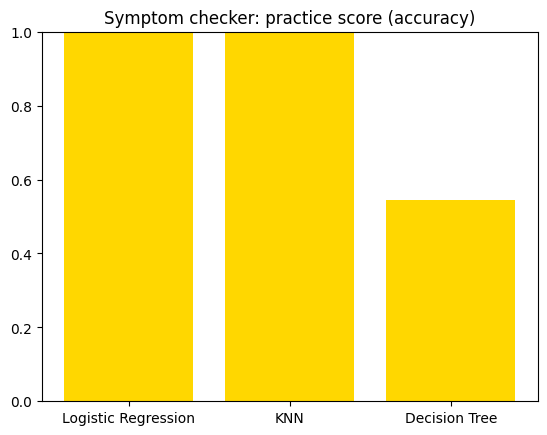

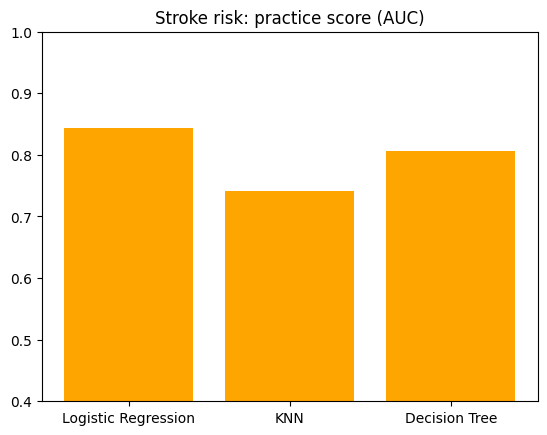

In [32]:
# STEP 10: scorecard charts
plt.bar(list(sym_scores.keys()), list(sym_scores.values()), color="gold")
plt.title("Symptom checker: practice score (accuracy)")
plt.ylim(0, 1)
plt.show()
plt.bar(list(str_auc.keys()), list(str_auc.values()), color="orange")
plt.title("Stroke risk: practice score (AUC)")
plt.ylim(0.4, 1)
plt.show()

In [33]:
# STEP 11: pick the winners
# the app runs inside a web page, so we can only use models whose numbers we can save:
# Logistic Regression and Decision Tree. KNN is compared for analysis only.
if sym_scores["Logistic Regression"] >= sym_scores["Decision Tree"]:
    best_sym = "Logistic Regression"
else:
    best_sym = "Decision Tree"

if str_auc["Logistic Regression"] >= str_auc["Decision Tree"]:
    best_str = "Logistic Regression"
else:
    best_str = "Decision Tree"

print("Symptom winner:", best_sym)
print("Stroke winner:", best_str)

sym_model = sym_models[best_sym]
sym_model.fit(Xs_train, ys_train)
str_model = str_models[best_str]
str_model.fit(Xt_train_s, yt_train)

Symptom winner: Logistic Regression
Stroke winner: Logistic Regression


LogisticRegression(class_weight='balanced', max_iter=1000)

In [34]:
# STEP 12: final exam on the test rows
print("Symptom exam accuracy:", round(accuracy_score(ys_test, sym_model.predict(Xs_test)), 3))
guess = str_model.predict(Xt_test_s)
chance = str_model.predict_proba(Xt_test_s)[:, 1]
print("Stroke exam accuracy:", round(accuracy_score(yt_test, guess), 3))
print("Stroke recall:", round(recall_score(yt_test, guess), 3))
print("Stroke precision:", round(precision_score(yt_test, guess), 3))
print("Stroke AUC:", round(roc_auc_score(yt_test, chance), 3))
print(confusion_matrix(yt_test, guess))

Symptom exam accuracy: 1.0
Stroke exam accuracy: 0.737
Stroke recall: 0.8
Stroke precision: 0.134
Stroke AUC: 0.841
[[713 259]
 [ 10  40]]


In [35]:
# STEP 13: try the two checkers
def check_symptoms(my_symptoms):
    row = pd.DataFrame(0, index=[0], columns=all_symptoms)
    for s in my_symptoms:
        row[s] = 1
    disease = sym_model.predict(row)[0]
    about = desc[desc["Disease"].str.strip() == disease]["Description"].values
    steps = prec[prec["Disease"].str.strip() == disease].iloc[:, 1:].values
    return disease, about, steps

def check_stroke(age, hyper, heart, sugar, bmi, smoking):
    person = scaler.transform(pd.DataFrame([[age, hyper, heart, sugar, bmi, smoking]], columns=stroke_features))
    return str_model.predict_proba(person)[0][1]

print(check_symptoms(all_symptoms[:3]))
print("Stroke chance:", round(check_stroke(70, 1, 1, 200, 32, 2), 2))
print("Stroke chance:", round(check_stroke(25, 0, 0, 90, 22, 0), 2))

('GERD', array(['Gastroesophageal reflux disease, or GERD, is a digestive disorder that affects the lower esophageal sphincter (LES), the ring of muscle between the esophagus and stomach. Many people, including pregnant women, suffer from heartburn or acid indigestion caused by GERD.'],
      dtype=object), array([['avoid fatty spicy food', 'avoid lying down after eating',
        'maintain healthy weight', 'exercise']], dtype=object))
Stroke chance: 0.91
Stroke chance: 0.05


In [36]:
# STEP 14: save the model numbers for the web app
# the web app uses Logistic Regression for both checkers, so we save its weights
if best_sym != "Logistic Regression" or best_str != "Logistic Regression":
    print("Winner is not Logistic Regression, so do not export. Ask for help.")
else:
    out = {}
    out["all_symptoms"] = all_symptoms
    out["stroke_features"] = stroke_features
    out["sym_type"] = best_sym
    out["sym_classes"] = list(sym_model.classes_)
    out["sym_coef"] = sym_model.coef_.tolist()
    out["sym_intercept"] = sym_model.intercept_.tolist()
    out["str_type"] = best_str
    out["str_mean"] = scaler.mean_.tolist()
    out["str_scale"] = scaler.scale_.tolist()
    out["str_coef"] = str_model.coef_[0].tolist()
    out["str_intercept"] = float(str_model.intercept_[0])

    # disease descriptions and precautions for the app
    out["about"] = {}
    out["steps"] = {}
    for i in range(len(desc)):
        out["about"][desc["Disease"][i].strip()] = desc["Description"][i]
    for i in range(len(prec)):
        row = prec.iloc[i]
        tips = []
        for x in row.values[1:]:
            if isinstance(x, str):
                tips.append(x)
        out["steps"][row["Disease"].strip()] = tips

    with open("model.json", "w") as f:
        json.dump(out, f)
    files.download("model.json")
    print("model.json saved")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

model.json saved
